# Экономика удержания: кому окупается скидка

Прошлая кампания BACK300 от 2025-10-01: промокод 300 ₽ по SMS, случайное деление treatment 70% / control 30%. По ней оцениваем, где скидка меняет поведение, сравниваем стратегии отбора и решаем «правило или модель».

Прибыль на получателя — разница средней маржи за 180 дней (net − cost, скидка уже вычтена) между treatment и control минус 5 ₽ за SMS. Интервалы прибыли — бутстреп, 2 000 повторов, ресемплинг внутри групп, фиксированный seed. Интервалы разницы долей — нормальное приближение.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn.db import connect
from churn.features import query
from churn.model import load, split
from churn.uplift import (
    HORIZONS, SMS, accessories_check, boot_weights, compare, curve, effects, fit_models, participants, risk,
    strategies, terciles, with_discount,
)

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "lines.linewidth": 2})
COLORS = {"правило": "#eb6834", "логрегрессия": "#2a78d6", "бустинг": "#1baf7a"}
GRAY = "#8a8984"

train, test = split(load())
models = fit_models(train)
print(f"правило: k = {models['k']}, X = {models['x']:.0f}")
with connect() as conn:
    df = participants(conn)
scores = risk(models, df)
w = boot_weights(df["treat"])
print(f"участников: {len(df)}, treatment {df['treat'].sum()}, control {(~df['treat']).sum()}")
print(f"последняя покупка больше 120 дней назад: {(df['days_since_last'] > 120).sum()}")

правило: k = 1.5, X = 30


участников: 6946, treatment 4863, control 2083
последняя покупка больше 120 дней назад: 1510


Признаки участников посчитаны на 2025-10-01 по заказам до этой даты, у всех участников, а не только у активных. У тех, чья последняя покупка была больше 120 дней назад, по нашему определению отток уже случился: модели на таких клиентах не обучались, и их оценки риска — экстраполяция.

## Сверки

In [2]:
with connect() as conn:
    back = query(conn, "select count(*) as n, sum(discount)::float8 as discount from raw.orders "
                       "where promo_code = 'BACK300' and status = 'delivered'").iloc[0]
seg = effects(df, "segment")
print(f"заказов BACK300: {back['n']}, списано скидок {back['discount']:,.0f} ₽")
print(f"SMS: {df['treat'].sum()} × {SMS} = {df['treat'].sum() * SMS:,} ₽")
seg[["b90_diff"]].astype(float).round(3).T

заказов BACK300: 754.0, списано скидок 226,200 ₽
SMS: 4863 × 5 = 24,315 ₽


,все,one_time,repeat_cat,repeat_dog,repeat_acc
b90_diff,0.066,0.042,0.021,0.147,0.072


## Эффект по сегментам

In [3]:
def interval(t, a, lo, hi, fmt="+.3f"):
    return t.apply(lambda r: f"{r[a]:{fmt}} [{r[lo]:{fmt}}; {r[hi]:{fmt}}]", axis=1)


def show(t):
    return pd.DataFrame({
        "n treatment": t["n_t"].astype(int), "n control": t["n_c"].astype(int),
        "bought_90 T": t["b90_t"].astype(float).round(3), "bought_90 C": t["b90_c"].astype(float).round(3),
        "bought_90 T − C": interval(t, "b90_diff", "b90_lo", "b90_hi"),
        "bought_120 T": t["b120_t"].astype(float).round(3), "bought_120 C": t["b120_c"].astype(float).round(3),
        "bought_120 T − C": interval(t, "b120_diff", "b120_lo", "b120_hi"),
        "маржа T, ₽": t["margin_t"].astype(float).round(0), "маржа C, ₽": t["margin_c"].astype(float).round(0),
        "прибыль на получателя, ₽": interval(t, "profit", "profit_lo", "profit_hi", "+.0f"),
        "redeemed в T": t["redeemed_t"].astype(float).round(3),
        "прибыль сегмента, ₽": t["total"].astype(float).round(0),
    })


show(seg)

,n treatment,n control,bought_90 T,bought_90 C,bought_90 T − C,bought_120 T,bought_120 C,bought_120 T − C,"маржа T, ₽","маржа C, ₽","прибыль на получателя, ₽",redeemed в T,"прибыль сегмента, ₽"
все,4863,2083,0.272,0.206,+0.066 [+0.045; +0.088],0.277,0.212,+0.065 [+0.044; +0.087],685.0,512.0,+168 [+106; +230],0.155,815961.0
one_time,2237,964,0.112,0.070,+0.042 [+0.022; +0.063],0.115,0.071,+0.045 [+0.024; +0.066],263.0,164.0,+94 [+38; +147],0.069,210103.0
repeat_cat,992,447,0.207,0.186,+0.021 [-0.023; +0.065],0.207,0.188,+0.019 [-0.025; +0.063],570.0,488.0,+77 [-62; +209],0.125,76007.0
repeat_dog,939,393,0.526,0.379,+0.147 [+0.089; +0.205],0.527,0.379,+0.148 [+0.090; +0.206],1460.0,1046.0,+408 [+219; +604],0.389,383440.0
repeat_acc,695,279,0.538,0.466,+0.072 [+0.003; +0.141],0.563,0.505,+0.057 [-0.012; +0.127],1161.0,1001.0,+155 [-18; +328],0.160,107629.0


Прибыль сегмента — прибыль на получателя × n treatment, то есть сколько кампания заработала на тех, кому реально отправили SMS.

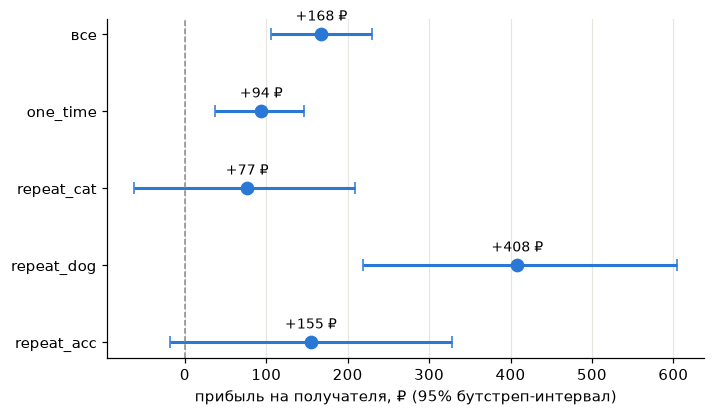

In [4]:
s = seg.astype(float)
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(s))[::-1]
ax.errorbar(s["profit"], y, xerr=[s["profit"] - s["profit_lo"], s["profit_hi"] - s["profit"]],
            fmt="o", color=COLORS["логрегрессия"], ecolor=COLORS["логрегрессия"], markersize=8, capsize=4)
for yi, v in zip(y, s["profit"]):
    ax.annotate(f"{v:+.0f} ₽", (v, yi), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.axvline(0, color=GRAY, linewidth=1, linestyle="--")
ax.set(yticks=y, yticklabels=s.index, xlabel="прибыль на получателя, ₽ (95% бутстреп-интервал)")
ax.grid(axis="y", visible=False)
plt.show()

## Эффект по корзинам риска

Терцили по оценке риска среди всех участников, отдельно для каждой оценки. Равные оценки правила разводятся по порядку строк.

In [5]:
def short(t):
    return pd.DataFrame({
        "n T": t["n_t"].astype(int), "n C": t["n_c"].astype(int),
        "bought_90 T": t["b90_t"].astype(float).round(3), "bought_90 C": t["b90_c"].astype(float).round(3),
        "прибыль на получателя, ₽": interval(t, "profit", "profit_lo", "profit_hi", "+.0f"),
    })


tert = {name: terciles(s) for name, s in scores.items()}
pd.concat({name: short(effects(df, t).drop("все")) for name, t in tert.items()})

n T  n C  bought_90 T  bought_90 C  \
правило      низкий   1609  707        0.552        0.474   
             средний  1628  687        0.189        0.111   
             высокий  1626  689        0.078        0.026   
логрегрессия низкий   1623  693        0.554        0.496   
             средний  1620  695        0.184        0.102   
             высокий  1620  695        0.078        0.020   
бустинг      низкий   1616  700        0.579        0.506   
             средний  1642  673        0.172        0.107   
             высокий  1605  710        0.066        0.004   

                     прибыль на получателя, ₽  
правило      низкий          +158 [+15; +292]  
             средний        +230 [+144; +314]  
             высокий         +142 [+98; +185]  
логрегрессия низкий          +161 [+27; +303]  
             средний        +196 [+121; +273]  
             высокий        +143 [+101; +184]  
бустинг      низкий          +166 [+33; +299]  
             средний         +162 [+81; +245]  
             высокий        +179 [+140; +220]

Терцили бустинга внутри каждого сегмента.

In [6]:
rows = {seg_: effects(d, tert["бустинг"][d.index]).drop("все") for seg_, d in df.groupby("segment", observed=True)}
short(pd.concat(rows))

/Users/kathiss/projects/churn-retention-economics/src/churn/uplift.py:101: RuntimeWarning: Mean of empty slice
  a, b = y[t].mean(), y[~t].mean()
/Users/kathiss/projects/churn-retention-economics/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/kathiss/projects/churn-retention-economics/src/churn/uplift.py:86: RuntimeWarning: invalid value encountered in scalar divide
  return (wt @ margin) / wt.sum(-1) - (wc @ margin) / wc.sum(-1) - SMS
/Users/kathiss/projects/churn-retention-economics/src/churn/uplift.py:86: RuntimeWarning: invalid value encountered in divide
  return (wt @ margin) / wt.sum(-1) - (wc @ margin) / wc.sum(-1) - SMS
/Users/kathiss/projects/churn-retention-economics/src/churn/uplift.py:107: RuntimeWarning: Mean of empty slice
  row |= {"margin_t": m[t].mean(), "margin_c": m[~t].mean(), "profit": p, "profit_lo": lo, "profit_hi": hi,


n T  n C  bought_90 T  bought_90 C  \
one_time   низкий    158   68        0.329        0.265   
           средний  1074  458        0.144        0.105   
           высокий  1005  438        0.043        0.002   
repeat_cat низкий    292  157        0.466        0.465   
           средний   276   93        0.170        0.108   
           высокий   424  197        0.052        0.000   
repeat_dog низкий    545  229        0.719        0.603   
           средний   221   89        0.276        0.101   
           высокий   173   75        0.237        0.027   
repeat_acc низкий    621  246        0.572        0.508   
           средний    71   33        0.268        0.152   
           высокий     3    0        0.000          NaN   

                   прибыль на получателя, ₽  
one_time   низкий         +177 [-210; +514]  
           средний          +79 [-10; +170]  
           высокий          +94 [+56; +134]  
repeat_cat низкий          +16 [-287; +307]  
           средний         +185 [-64; +412]  
           высокий         +163 [+92; +242]  
repeat_dog низкий           +269 [+7; +532]  
           средний        +520 [+278; +757]  
           высокий        +716 [+496; +937]  
repeat_acc низкий          +145 [-41; +328]  
           средний        +191 [-217; +580]  
           высокий        +nan [+nan; +nan]

У повторных покупателей аксессуаров в высокую терциль бустинга попали 3 клиента, все в treatment: оценки нет. Терцили бустинга считаются по всем участникам, поэтому внутри сегментов корзины неравные.

## Стратегии при одном размере кампании

Размер — 50% участников с округлением вниз. Прибыль стратегии = (средняя маржа в treatment − в control среди отобранных − 5) × размер. «Случайные» — средняя прибыль на получателя по всей кампании. Стратегия по сегментам берёт сегменты, у которых нижняя граница интервала прибыли на получателя больше нуля, со всеми их участниками, поэтому её размер свой.

In [7]:
strat = strategies(df, scores, w=w)
print(f"размер: {int(len(df) * 0.5)} из {len(df)}")
pd.DataFrame({
    "размер": strat["размер"].astype(int),
    "на получателя, ₽": interval(strat, "на получателя", "lo", "hi", "+.0f"),
    "прибыль, ₽": interval(strat, "прибыль", "прибыль lo", "прибыль hi", "+,.0f"),
})

размер: 3473 из 6946


,размер,"на получателя, ₽","прибыль, ₽"
случайные,3473,+168 [+106; +230],"+582,734 [+366,767; +797,700]"
топ по риску: правило,3473,+155 [+112; +199],"+537,997 [+387,405; +691,406]"
топ по риску: логрегрессия,3473,+148 [+105; +190],"+515,060 [+363,967; +661,303]"
топ по риску: бустинг,3473,+166 [+125; +206],"+577,114 [+435,453; +714,303]"
"сегменты: one_time, repeat_dog",4533,+192 [+119; +268],"+871,318 [+538,279; +1,213,995]"


,размер,"случайные, тыс. ₽","правило, тыс. ₽","логрегрессия, тыс. ₽","бустинг, тыс. ₽"
охват,,,,,
0.1,694,116,82,64,115
0.2,1389,233,204,188,248
0.3,2083,350,298,303,359
0.4,2778,466,372,400,492
0.5,3473,583,538,515,577
0.6,4167,699,775,679,745
0.7,4862,816,875,831,803
0.8,5556,932,1020,857,1020
0.9,6251,1049,1062,958,941


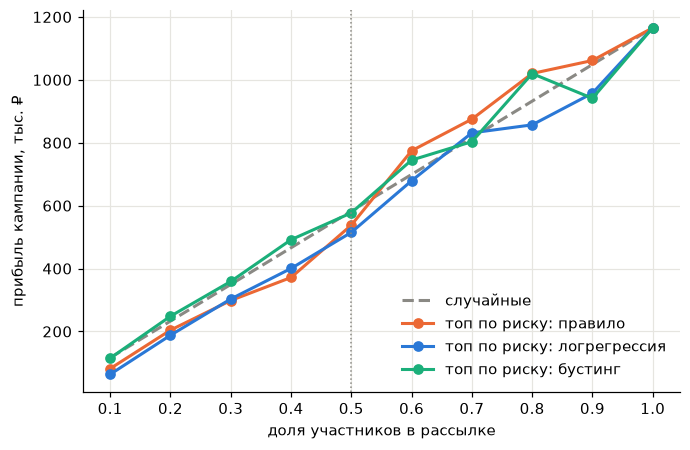

In [8]:
cur = curve(df, scores)
display((cur / 1000).round(0).astype(int).assign(размер=cur["размер"]).rename(
    columns=lambda c: c if c == "размер" else f"{c}, тыс. ₽"))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cur.index, cur["случайные"] / 1000, color=GRAY, linestyle="--", label="случайные")
for name in scores:
    ax.plot(cur.index, cur[name] / 1000, color=COLORS[name], marker="o", markersize=6, label=f"топ по риску: {name}")
ax.axvline(0.5, color=GRAY, linewidth=1, linestyle=":")
ax.set(xlabel="доля участников в рассылке", ylabel="прибыль кампании, тыс. ₽", xticks=cur.index)
ax.legend(frameon=False)
plt.show()

## Правило или модель

Критерий из документа: модель берём, только если при том же размере кампании она даёт больше прибыли и 95% бутстреп-интервал разницы целиком выше нуля. Сравниваем лучшую из двух моделей по прибыли на размере 50% с правилом; бутстреп парный — одни и те же повторы для обеих стратегий.

In [9]:
model_profit = strat.loc[[f"топ по риску: {m}" for m in ("логрегрессия", "бустинг")], "прибыль"]
best = model_profit.astype(float).idxmax().removeprefix("топ по риску: ")
cmp = pd.DataFrame({m: compare(df, scores["правило"], scores[m], w=w) for m in ("логрегрессия", "бустинг")}).T
display(cmp.round(0))
r = cmp.loc[best]
accepted = r["lo"] > 0
print(f"Лучшая модель — {best}: {r['разница']:+,.0f} ₽ к правилу [{r['lo']:+,.0f}; {r['hi']:+,.0f}], "
      + ("интервал выше нуля, берём модель." if accepted else "интервал включает ноль, оставляем правило."))

,размер,разница,lo,hi
логрегрессия,3473.0,-22937.0,-134056.0,79654.0
бустинг,3473.0,39118.0,-88388.0,157793.0


Лучшая модель — бустинг: +39,118 ₽ к правилу [-88,388; +157,793], интервал включает ноль, оставляем правило.


## Устойчивость

Прибыль на получателя по сегментам при горизонте маржи 90, 180 и 270 дней (270 — до 2026-06-28).

In [10]:
by_h = {f"{h} дней": interval(effects(df, "segment", f"margin_{h}"), "profit", "profit_lo", "profit_hi", "+.0f")
        for h in HORIZONS}
pd.DataFrame(by_h)

,90 дней,180 дней,270 дней
все,+87 [+52; +124],+168 [+106; +230],+221 [+136; +306]
one_time,+51 [+17; +82],+94 [+38; +147],+122 [+45; +195]
repeat_cat,+32 [-43; +105],+77 [-62; +209],+112 [-72; +294]
repeat_dog,+221 [+115; +335],+408 [+219; +604],+551 [+293; +819]
repeat_acc,+70 [-40; +177],+155 [-18; +328],+174 [-55; +403]


Стоимость скидки 200 и 400 ₽: поведение то же, у redeemed меняется только списанная скидка.

In [11]:
by_d = {}
for d in (200, 300, 400):
    df[f"margin_d{d}"] = with_discount(df, d)
    by_d[f"{d} ₽"] = interval(effects(df, "segment", f"margin_d{d}"), "profit", "profit_lo", "profit_hi", "+.0f")
pd.DataFrame(by_d)

,200 ₽,300 ₽,400 ₽
все,+183 [+121; +245],+168 [+106; +230],+152 [+91; +214]
one_time,+101 [+44; +154],+94 [+38; +147],+87 [+31; +139]
repeat_cat,+89 [-50; +224],+77 [-62; +209],+64 [-73; +197]
repeat_dog,+447 [+257; +646],+408 [+219; +604],+369 [+181; +565]
repeat_acc,+171 [-2; +344],+155 [-18; +328],+139 [-33; +312]


Порог 180 дней для аксессуаров: на точке проверки 2026-01-01 у клиентов с main_category = accessories целевая переменная пересчитана по окну [T, T + 180), модели не переобучались.

In [12]:
with connect() as conn:
    acc = accessories_check(conn, test, risk(models, test))
acc

,доля churn,правило,логрегрессия,бустинг
порог,,,,
120,0.419,0.670,0.718,0.724
180,0.396,0.664,0.716,0.724


## Итог

- Кампания в целом окупилась: +168 ₽ на получателя [+106; +230]. Надёжно окупаются repeat_dog (+408 ₽) и one_time (+94 ₽). У repeat_cat и repeat_acc интервал включает ноль.
- Риск оттока не показывает, где скидка работает: прибыль на получателя по терцилям риска почти одинакова, и топ-50% по риску не лучше случайных 50%. Внутри repeat_dog прибыль растёт с риском, в остальных сегментах интервалы слишком широкие.
- Отбор по сегментам (one_time и repeat_dog, 4 533 человека) даёт +871 тыс. ₽ и +192 ₽ на получателя — больше, чем любая стратегия по риску. Размер у неё свой, так что сравнение с риском не при равном размере.
- Правило или модель: лучшая модель — бустинг, +39 тыс. ₽ к правилу на 3 473 получателях, интервал [−88; +158] тыс. ₽ включает ноль. Оставляем правило.
- Устойчивость: при горизонте 90 и 270 дней и скидке 200 и 400 ₽ окупаемые сегменты те же — repeat_dog и one_time; у repeat_acc при скидке 200 ₽ нижняя граница −2 ₽. С порогом 180 дней для аксессуаров порядок по PR-AUC тот же: бустинг ≥ логрегрессия > правило.
- У 1 510 участников последняя покупка была больше 120 дней назад: по нашему определению они уже ушли, и для них оценки риска моделей — экстраполяция.